# AI-Based Crop Health Monitoring Using Drone Multispectral Data

Masai School × IIT Roorkee (iHUB DivyaSampark) capstone.

**Goal:** predict whether a spatial observation in a field is *Stressed* or *Healthy* from processed drone
vegetation indices, map predicted stress across the field, and turn that map into a drone inspection plan.

The notebook calls the same functions as `python -m src.train` (in `src/train.py`), so the numbers here and in
`reports/metrics.json` come from the same code. The last cell checks that they match. Random seed: **42**.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from src import train as T
from src.config import FEATURES, GRID_COLS, SEED, FIG_DIR, REPORTS_DIR
from src.data import load_data, split, make_target
from src.models import make_pipeline, base_estimators
from sklearn.base import clone

T.setup_mlflow("crop-stress-notebook")   # notebook runs go to their own MLflow experiment
def fig(name, width=None): display(Image(filename=str(FIG_DIR / name), width=width))
print("seed =", SEED)

2026/10/18 18:02:45 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/claude/venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


seed = 42


## 1. Data understanding

### What each column means and how it relates to stress

| Column | What it measures | Link to crop stress |
|---|---|---|
| `ndvi_mean/std/min/max` | NDVI = (NIR − Red)/(NIR + Red), summarised over the observation's pixels | Healthy leaves reflect a lot of near-infrared and absorb red light, so NDVI is high. Stress (water, nutrients, disease) breaks down chlorophyll and leaf structure, so NDVI drops. `std` shows how patchy the plot is; `min` catches weak spots inside it. |
| `gndvi` | Like NDVI but uses green instead of red | More sensitive to chlorophyll concentration at high canopy cover, where NDVI saturates. Good for early nitrogen stress. |
| `savi` | Soil-Adjusted Vegetation Index, NDVI with a soil correction factor L | Reduces the soil-background effect when the canopy is sparse (early season, gaps). |
| `evi` | Enhanced Vegetation Index (uses blue to correct for the atmosphere and canopy background) | Stays responsive in dense canopies where NDVI saturates. |
| `red_edge_1/2` | Reflectance in the red-edge band (~700–740 nm) | The red edge shifts to shorter wavelengths when chlorophyll drops, often *before* visible symptoms, so it is an early-stress signal. |
| `nir_reflectance` | Raw near-infrared reflectance | Driven by the internal structure of the leaf (mesophyll). It falls when leaves wilt or senesce. |
| `soil_brightness` | How much bright bare soil the sensor sees | High values mean thin canopy or exposed soil, which inflates the error in vegetation indices. |
| `canopy_density` | Fraction of ground covered by canopy | Low cover means poor emergence, lodging or die-back. |
| `moisture_index` | Water-sensitive index (NDWI/NDMI-type, using NIR and SWIR) | Low values mean water stress. This usually shows up before NDVI drops. |
| `grid_x`, `grid_y` | Position of the observation on a 20×20 field grid | Used for mapping only, **not** as model inputs (see below). |

In [2]:
df = load_data()
train_df, test_df = split(df)                       # stratified 80/20 split FIRST
y_train, y_test = make_target(train_df), make_target(test_df)
print("shape:", df.shape)
print("train / test rows:", len(train_df), len(test_df))
print("stressed share  train / test:", round(y_train.mean(), 4), round(y_test.mean(), 4))
df.head()

shape: (1200, 16)
train / test rows: 960 240
stressed share  train / test: 0.35 0.35


,ndvi_mean,ndvi_std,ndvi_min,ndvi_max,gndvi,savi,evi,red_edge_1,red_edge_2,nir_reflectance,soil_brightness,canopy_density,moisture_index,grid_x,grid_y,crop_health_label
0,0.462178,0.118574,0.345162,0.527650,0.434070,0.493184,0.426272,0.538210,0.387860,0.715725,0.531091,0.586647,0.679785,9,0,Healthy
1,0.865500,0.023196,0.814436,1.056953,0.855039,0.887622,0.807505,0.200828,0.391693,0.350926,0.304631,0.418664,0.926373,4,8,Healthy
2,0.712396,0.022876,0.539486,0.881657,0.628224,0.721757,0.708308,0.139121,0.474993,0.479509,0.394532,0.829622,0.443202,6,7,Healthy
3,0.619061,0.062069,0.515087,0.696248,0.578767,0.609120,0.640899,0.494059,0.354945,0.555526,0.594686,0.882743,0.788671,4,5,Healthy
4,0.309213,0.083524,0.178098,0.466014,0.357456,0.357234,0.434805,0.517743,0.152411,0.767144,0.781283,0.916408,0.637918,14,19,Healthy


In [3]:
eda, corr = T.eda(df, train_df)
print("class counts:", eda["class_counts"], "| stressed share:", eda["stressed_share"])
print("missing values:", eda["missing_values_total"], "| duplicate rows:", eda["duplicate_rows"])
print("IQR outliers (all features):", sum(eda["iqr_outliers_per_feature"].values()))
print("values above the physical maximum of 1:", eda["out_of_physical_range"])
print("grid:", eda["grid"])
df[FEATURES].describe().T.round(3)

class counts: {'Healthy': 780, 'Stressed': 420} | stressed share: 0.35
missing values: 0 | duplicate rows: 0
IQR outliers (all features): 0
values above the physical maximum of 1: {'ndvi_max>1': 52, 'evi>1': 4}
grid: {'x_range': [0, 19], 'y_range': [0, 19], 'occupied_cells': 379, 'total_cells': 400, 'obs_per_cell_mean': 3.17, 'obs_per_cell_min': 1, 'obs_per_cell_max': 11}


,count,mean,std,min,25%,50%,75%,max
ndvi_mean,1200.0,0.549,0.206,0.203,0.367,0.557,0.729,0.900
ndvi_std,1200.0,0.085,0.037,0.020,0.052,0.086,0.116,0.150
ndvi_min,1200.0,0.426,0.209,0.021,0.247,0.435,0.603,0.836
ndvi_max,1200.0,0.673,0.210,0.265,0.488,0.671,0.853,1.088
gndvi,1200.0,0.549,0.210,0.085,0.366,0.551,0.719,0.973
savi,1200.0,0.548,0.211,0.119,0.365,0.546,0.728,0.975
evi,1200.0,0.547,0.218,0.068,0.369,0.553,0.733,1.030
red_edge_1,1200.0,0.347,0.143,0.100,0.225,0.347,0.470,0.600
red_edge_2,1200.0,0.354,0.144,0.101,0.233,0.353,0.479,0.600
nir_reflectance,1200.0,0.549,0.204,0.200,0.368,0.544,0.731,0.899


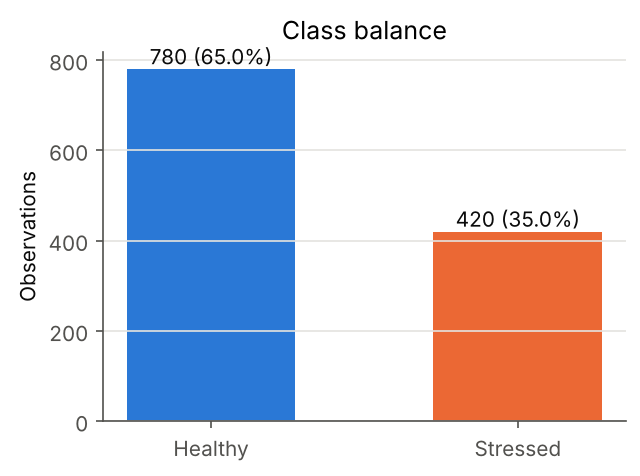

In [4]:
fig("class_balance.png", 380)

**Class balance:** 65% Healthy and 35% Stressed. That is mildly imbalanced, so I use a stratified split and
stratified CV, report F1, PR curves and ROC-AUC rather than accuracy alone, and let the tuner try
`class_weight="balanced"`.

Correlation with the Stressed label (training set):
ndvi_mean         -0.671
ndvi_min          -0.660
evi               -0.653
ndvi_max          -0.652
savi              -0.649
gndvi             -0.647
canopy_density    -0.326
moisture_index    -0.224
grid_y            -0.065
nir_reflectance   -0.015
red_edge_1        -0.006
grid_x            -0.002
ndvi_std           0.016
soil_brightness    0.063
red_edge_2         0.066

Near-duplicate feature pairs (|r| > 0.9):
  ndvi_mean  ~ ndvi_min   r = 0.978
  ndvi_mean  ~ ndvi_max   r = 0.98
  ndvi_mean  ~ gndvi      r = 0.973
  ndvi_mean  ~ savi       r = 0.981
  ndvi_mean  ~ evi        r = 0.963
  ndvi_min   ~ ndvi_max   r = 0.957
  ndvi_min   ~ gndvi      r = 0.953
  ndvi_min   ~ savi       r = 0.96
  ndvi_min   ~ evi        r = 0.939
  ndvi_max   ~ gndvi      r = 0.953
  ndvi_max   ~ savi       r = 0.962
  ndvi_max   ~ evi        r = 0.944
  gndvi      ~ savi       r = 0.951
  gndvi      ~ evi        r = 0.943
  savi       ~ evi        r 

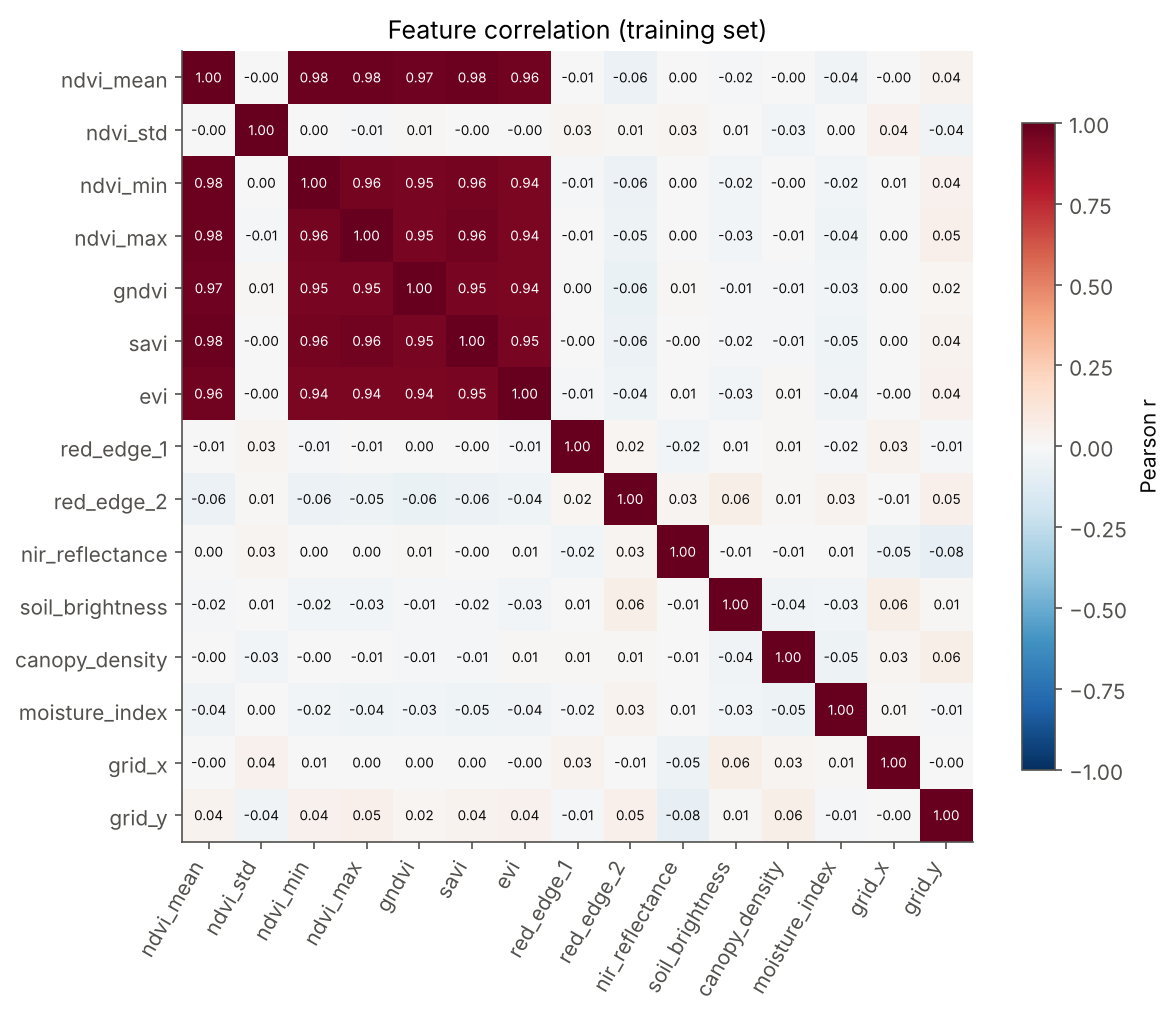

In [5]:
print("Correlation with the Stressed label (training set):")
print(pd.Series(eda["corr_with_stressed_train"]).to_string())
print("\nNear-duplicate feature pairs (|r| > 0.9):")
for a, b, r in eda["near_duplicate_pairs_abs_r_gt_0.9"]: print(f"  {a:10s} ~ {b:10s} r = {r}")
print("\nr(nir_reflectance, ndvi_mean) =", eda["nir_vs_ndvi_r"])
fig("correlation_heatmap.png", 650)

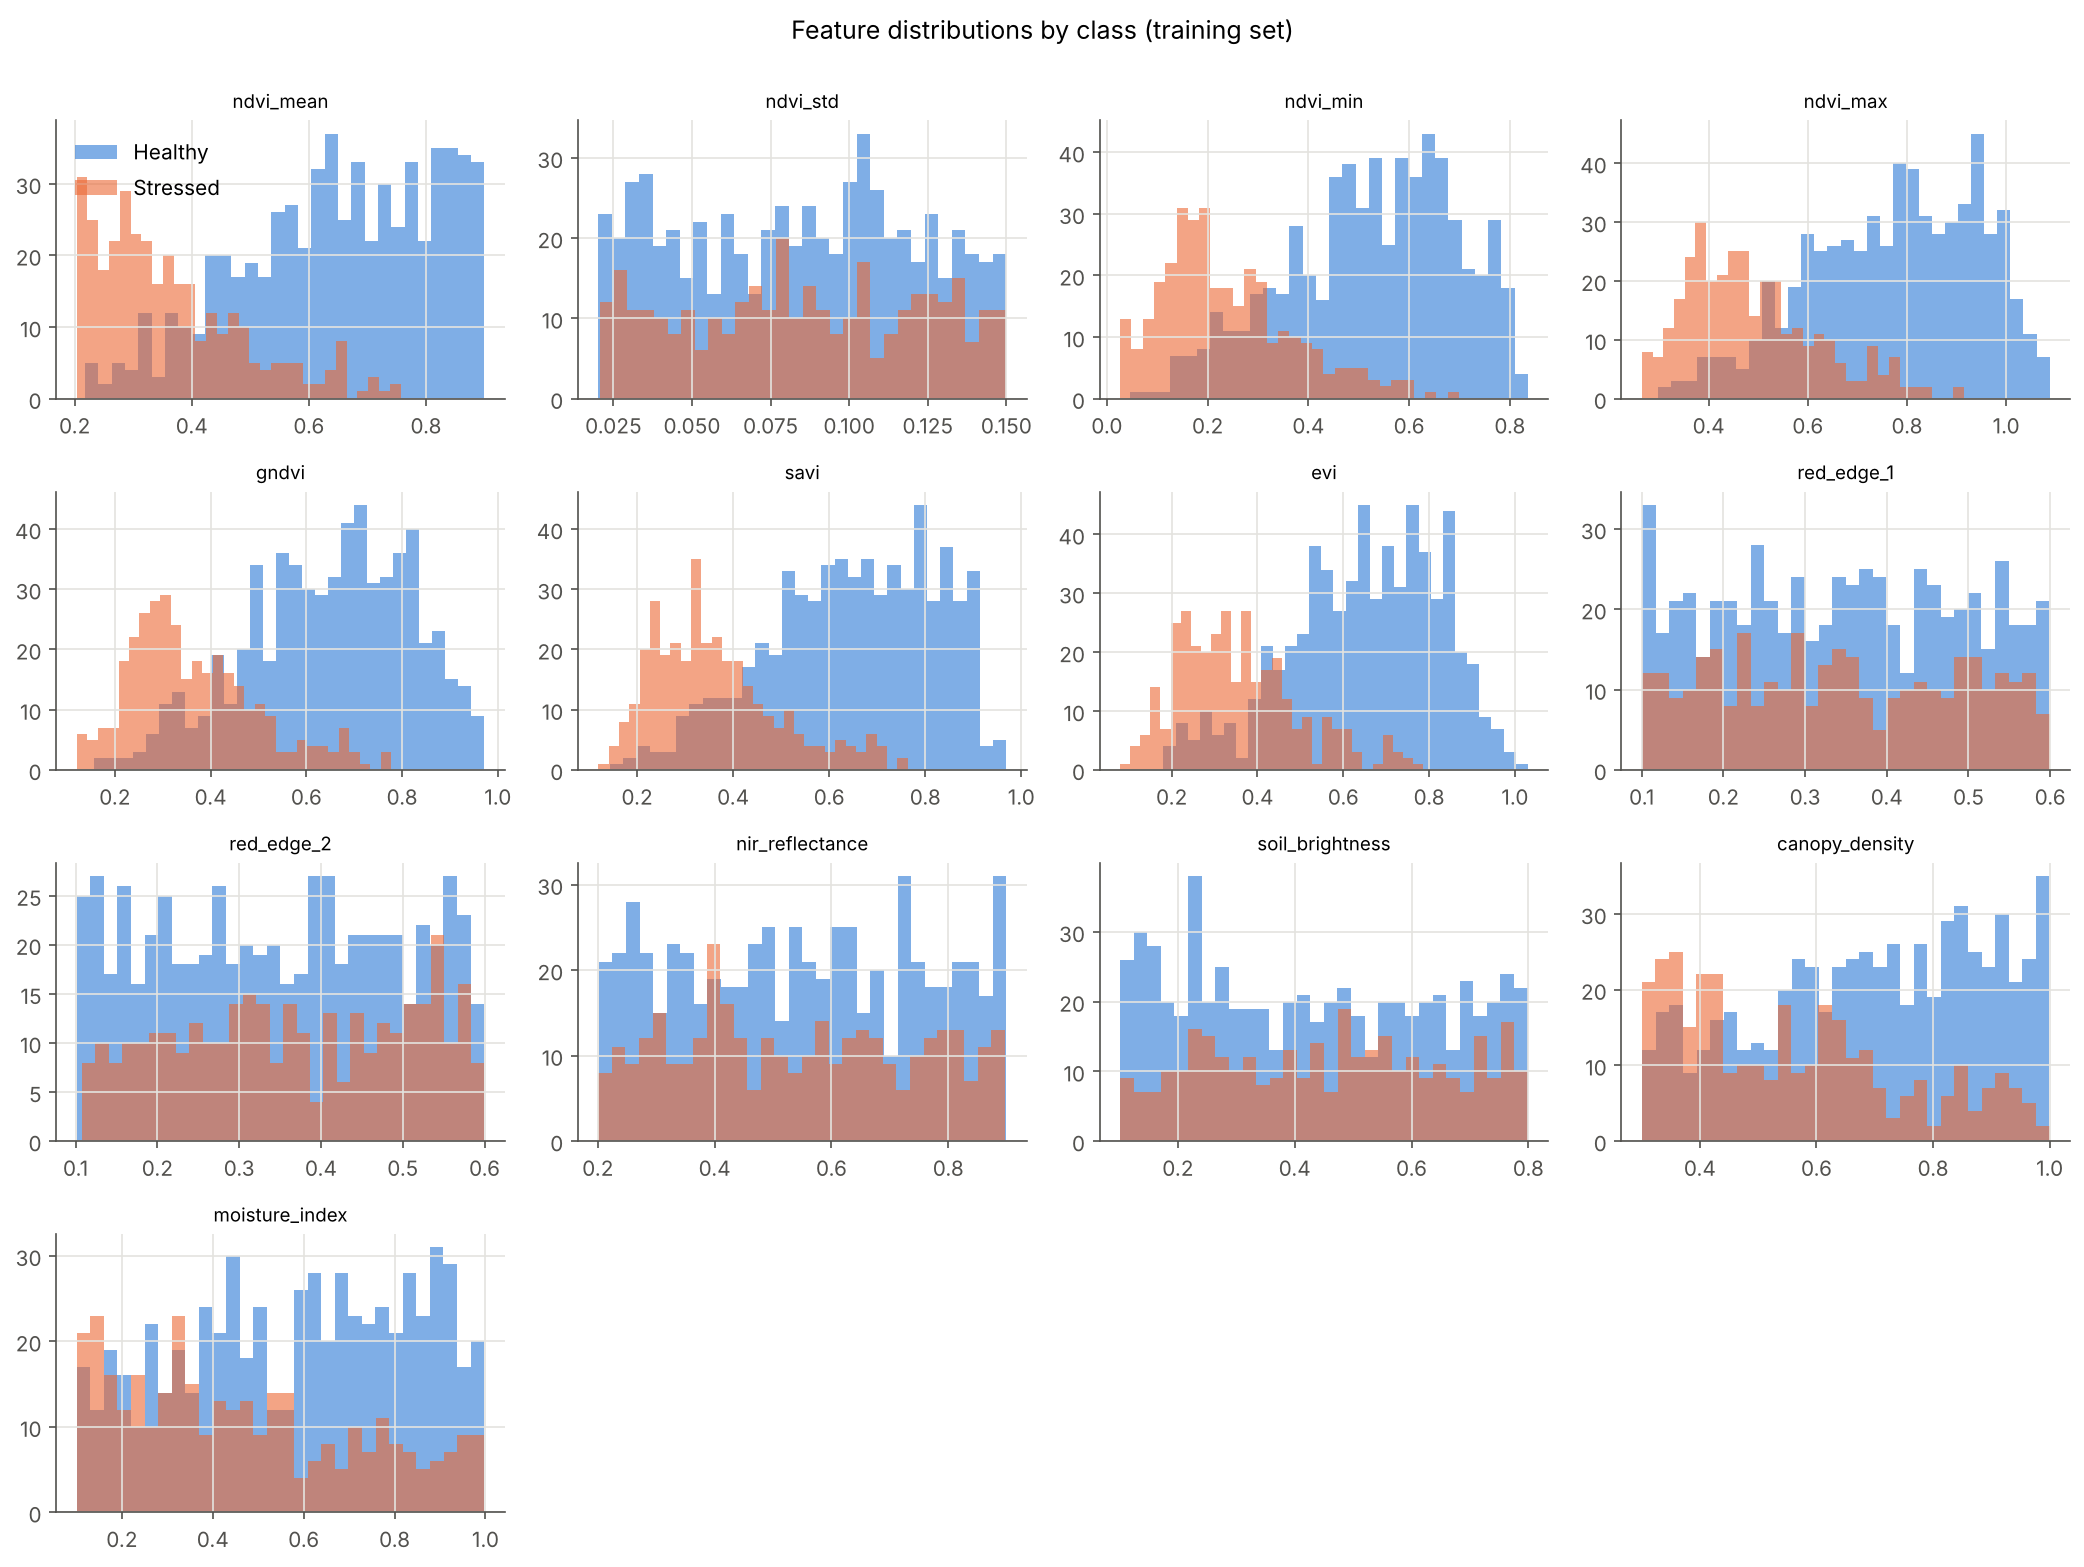

In [6]:
fig("feature_distributions.png")

### Surprising things in the EDA

1. **Near-duplicate features.** NDVI mean/min/max, GNDVI, SAVI and EVI are all pairwise correlated at r ≥ 0.93. They
   carry almost the same information, which matters for linear-model coefficients and for how SHAP spreads credit.
2. **Physically inconsistent bands.** NIR reflectance is essentially uncorrelated with NDVI (r ≈ 0), and so are
   the red-edge bands. In real imagery NDVI is *computed from* NIR, so they would be strongly correlated. This is
   a sign the indices were generated independently, i.e. the data is **synthetic** (the source file is
   literally named "Synthetic Multispectral Crops Data").
3. **52 `ndvi_max` values and 4 `evi` values are above 1.0**, which is impossible for NDVI. I keep them because
   there are few and they don't affect the model, but real data would need a QA filter.
4. No missing values, no duplicate rows, and no IQR outliers. The imputer is in the pipeline anyway, so the
   deployed model can handle a missing band.

### Leakage audit: is the label a formula of the inputs?

The near-perfect cross-validation scores below made me check whether the label is a deterministic rule.

In [7]:
la = eda["leakage_audit"]
print("weights recovered from the TRAINING set:", la["recovered_weights_train"])
print("training accuracy of a single cut on that composite:", la["train_accuracy_single_cut"])
print("rounded rule:", la["rule"])
print("cut value:", la["rule_cut_value"], "| accuracy of the rule on ALL 1200 rows:", la["rule_accuracy_all_rows"])

weights recovered from the TRAINING set: {'ndvi_mean': 0.554, 'canopy_density': 0.275, 'moisture_index': 0.17}
training accuracy of a single cut on that composite: 0.9729
rounded rule: stressed <=> 0.5*ndvi_mean + 0.3*canopy_density + 0.2*moisture_index is in the bottom 35% of the field
cut value: 0.5266 | accuracy of the rule on ALL 1200 rows: 1.0


**Finding: the label is a deterministic formula.** `Stressed` ⇔ `0.5·ndvi_mean + 0.3·canopy_density +
0.2·moisture_index` is in the bottom 35% of the field. That rule reproduces **100% of the 1,200 labels**.
This is a form of target leakage built into the dataset: the target was generated from three of the input
columns, with no field-scouting ground truth and no label noise.

What that means for the rest of the project:
* A linear model can, in principle, reach a perfect score. Near-perfect metrics here show the model
  **re-discovered the labelling rule**. They do not show it would detect real stress this well.
* I still run the full, honest workflow (it is what would be used on real data) and report every number, but I
  interpret the results with this in mind.
* `grid_x/grid_y` are excluded from the features: they are not plant signals and wouldn't transfer to another field.

## 2. Machine-learning model

### 2a. Baselines and model comparison (stratified 5-fold CV on the training set only)

Every model is an sklearn `Pipeline`: select features → median imputation → standard scaling → classifier.
Because imputation and scaling are inside the pipeline, `cross_validate` refits them on each training fold,
so the validation fold never leaks into the preprocessing. The test set is not touched here.

In [8]:
cv_df = T.compare_models(train_df, y_train)
cv_df[["model","f1_mean","f1_std","roc_auc_mean","roc_auc_std","precision_mean","recall_mean","accuracy_mean"]]

,model,f1_mean,f1_std,roc_auc_mean,roc_auc_std,precision_mean,recall_mean,accuracy_mean
0,logreg,0.9685,0.0127,0.9987,0.0009,0.9710,0.9672,0.9781
1,svm_rbf,0.9510,0.0117,0.9959,0.0016,0.9469,0.9553,0.9656
2,xgboost,0.9361,0.0176,0.9941,0.0033,0.9548,0.9197,0.9563
3,lightgbm,0.9250,0.0135,0.9934,0.0027,0.9319,0.9197,0.9479
4,random_forest,0.8920,0.0288,0.9819,0.0064,0.9081,0.8781,0.9260
5,dummy_majority,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.6500


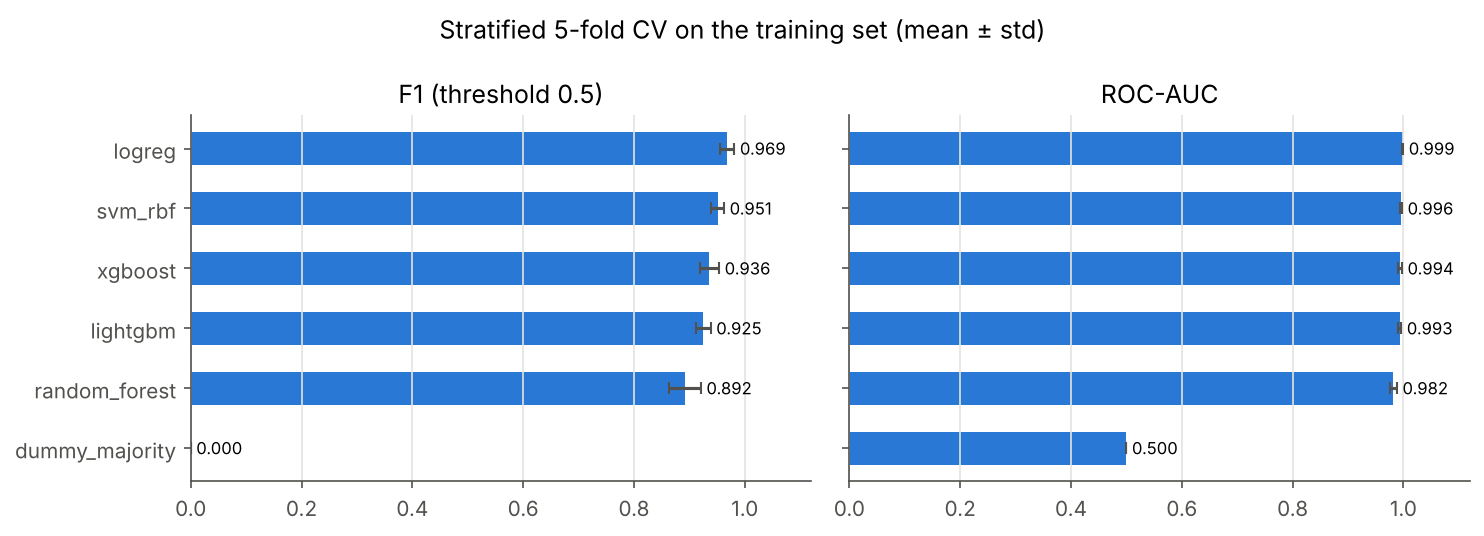

In [9]:
fig("cv_comparison.png")

* The **majority-class dummy** predicts "Healthy" every time. That gives 65% accuracy but F1 = 0 and ROC-AUC = 0.5,
  which is why accuracy alone is misleading here.
* **Logistic regression** is the strongest model. That fits the leakage finding: the true boundary is a
  straight line (a weighted sum), and a linear model represents it exactly. Tree models have to approximate an
  oblique boundary with axis-aligned steps, so they come out lower.

### 2b. Hyper-parameter tuning of the two best models

`RandomizedSearchCV` (40 candidates, same 5 folds). ROC-AUC already saturates at about 1.000, so it can't tell
candidates apart. The search therefore **refits on log-loss**, a proper scoring rule that still rewards
confident, correct probabilities. Every candidate is logged to MLflow.

In [10]:
candidates = [m for m in cv_df["model"] if m != "dummy_majority"][:2]
tuned = {name: T.tune(train_df, y_train, name) for name in candidates}
tuned_df = pd.DataFrame([v[0] for v in tuned.values()])
untuned = cv_df.set_index("model")
tuned_df["f1_gain_vs_untuned"] = [round(r.f1_mean - untuned.loc[r.model, "f1_mean"], 4) for r in tuned_df.itertuples()]
tuned_df["auc_gain_vs_untuned"] = [round(r.roc_auc_mean - untuned.loc[r.model, "roc_auc_mean"], 4) for r in tuned_df.itertuples()]
best_name = max(tuned, key=lambda k: tuned[k][0]["neg_log_loss_mean"])
best_pipe = tuned[best_name][1]
print("best tuned model:", best_name)
tuned_df[["model","best_params","f1_mean","f1_std","roc_auc_mean","roc_auc_std","neg_log_loss_mean","f1_gain_vs_untuned","auc_gain_vs_untuned"]]

best tuned model: logreg


,model,best_params,f1_mean,f1_std,roc_auc_mean,roc_auc_std,neg_log_loss_mean,f1_gain_vs_untuned,auc_gain_vs_untuned
0,logreg,"{'clf__C': 13.921548533046511, 'clf__class_wei...",0.9912,0.0071,1.000,0.0000,-0.0150,0.0227,0.0013
1,svm_rbf,"{'clf__C': 48.696409415209004, 'clf__class_wei...",0.9777,0.0104,0.999,0.0009,-0.0507,0.0267,0.0031


### 2c. Error analysis (out-of-fold predictions on the training set)

I don't look at the test set for this step. Each training row gets a prediction from a model that never saw
it (`cross_val_predict`), and I study the misclassified rows.

In [11]:
rule_cut = eda["leakage_audit"]["rule_cut_value"]
ea_before, errs_before, _ = T.error_analysis(train_df, y_train, best_pipe, rule_cut)
print(ea_before)
errs_before[["ndvi_mean","canopy_density","moisture_index","composite","dist_to_boundary","y_true","oof_proba"]]

{'n_errors': 6, 'false_positives': 5, 'false_negatives': 1, 'max_dist_to_boundary_errors': 0.0027, 'median_dist_to_boundary_all': 0.095, 'share_of_rows_within_error_band': 0.0115}


,ndvi_mean,canopy_density,moisture_index,composite,dist_to_boundary,y_true,oof_proba
762,0.373942,0.574489,0.842873,0.5279,0.0013,0,0.688
706,0.425648,0.711554,0.491052,0.5245,0.0021,1,0.489
628,0.225678,0.927084,0.691724,0.5293,0.0027,0,0.712
375,0.423283,0.552565,0.750731,0.5276,0.0010,0,0.754
964,0.402086,0.769406,0.486731,0.5292,0.0026,0,0.603
102,0.420049,0.871989,0.274746,0.5266,0.0000,0,0.698


**Finding.** Every misclassified row lies within about 0.003 of the decision boundary on the composite score,
while the median row is about 0.095 from it. Only about 1% of rows fall in that narrow band. These are
borderline plots, not mislabelled or noisy ones. Most of the errors are false alarms (Healthy flagged as
Stressed).

**Why, and what to change.** Near the boundary, small amounts of noise decide the class. The model gets five
noisy near-copies of NDVI (`ndvi_min`, `ndvi_max`, `gndvi`, `savi`, `evi`, all r > 0.96 with `ndvi_mean`). Spreading
weight across these copies adds noise to the score right where precision matters. **Change:** drop features with
|r| > 0.9 to an earlier-kept feature. The threshold is measured on the training set only, and the change uses
the EDA, not the label formula. Then I re-run the identical search and compare on the same CV folds.

In [12]:
from src.features import drop_correlated
kept, dropped = drop_correlated(train_df, FEATURES, 0.9)
print("dropped:", dropped); print("kept:", kept)
after_cv, after_pipe = T.tune(train_df, y_train, best_name, kept, run_label="tune_dedup")
ea_after, errs_after, _ = T.error_analysis(train_df, y_train, after_pipe, rule_cut)
cols = ["f1_mean","f1_std","roc_auc_mean","precision_mean","recall_mean","neg_log_loss_mean"]
ba = pd.DataFrame({"before (13 features)": {**{c: tuned[best_name][0][c] for c in cols}, "oof_errors": ea_before["n_errors"],
                                             "false_pos": ea_before["false_positives"], "false_neg": ea_before["false_negatives"]},
                   f"after ({len(kept)} features)": {**{c: after_cv[c] for c in cols}, "oof_errors": ea_after["n_errors"],
                                             "false_pos": ea_after["false_positives"], "false_neg": ea_after["false_negatives"]}})
adopt = (after_cv["neg_log_loss_mean"] > tuned[best_name][0]["neg_log_loss_mean"]
         and after_cv["f1_mean"] >= tuned[best_name][0]["f1_mean"])
final_pipe = after_pipe if adopt else best_pipe
final_features = kept if adopt else FEATURES
print("adopt change:", adopt)
ba

dropped: {'ndvi_min': ('ndvi_mean', 0.978), 'ndvi_max': ('ndvi_mean', 0.98), 'gndvi': ('ndvi_mean', 0.973), 'savi': ('ndvi_mean', 0.981), 'evi': ('ndvi_mean', 0.963)}
kept: ['ndvi_mean', 'ndvi_std', 'red_edge_1', 'red_edge_2', 'nir_reflectance', 'soil_brightness', 'canopy_density', 'moisture_index']


adopt change: True


,before (13 features),after (8 features)
f1_mean,0.9912,0.9941
f1_std,0.0071,0.0055
roc_auc_mean,1.0000,1.0000
precision_mean,0.9855,0.9883
recall_mean,0.9970,1.0000
neg_log_loss_mean,-0.0150,-0.0122
oof_errors,6.0000,4.0000
false_pos,5.0000,4.0000
false_neg,1.0000,0.0000


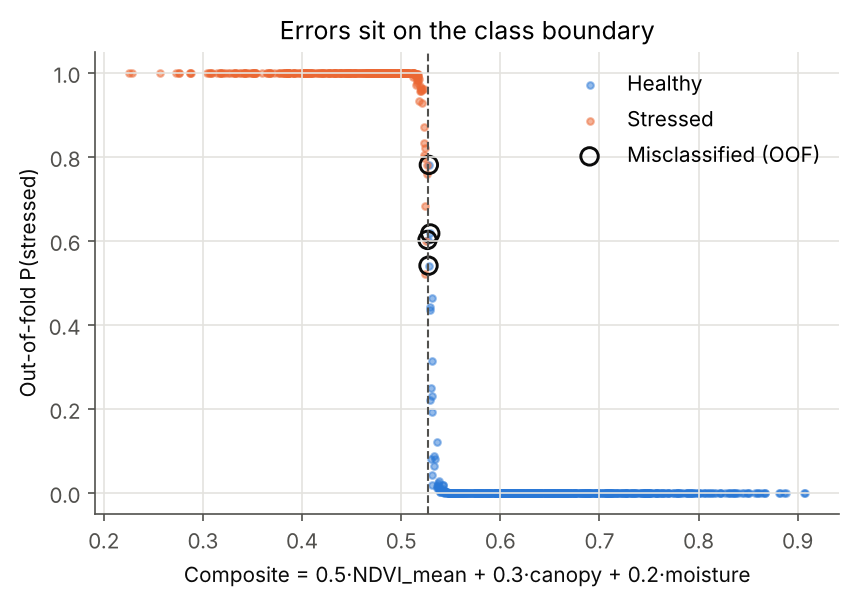

In [13]:
_, _, oof_final = T.error_analysis(train_df, y_train, final_pipe, rule_cut)   # redraw figure for the kept model
fig("error_analysis.png", 600)

### 2d. Choosing the decision threshold

Missing a stressed patch costs more than an extra drone pass: an untreated problem spreads and costs yield,
while a false alarm costs a few minutes of flight. So I pick the threshold that **maximises F2**, which weighs
recall twice as much as precision. The choice is made on out-of-fold *training* predictions, never on the test
set, and ties go to the lower (more cautious) threshold.

chosen threshold: 0.47
 threshold  precision  recall     f1     f2  fn  fp
      0.30     0.9767   1.000 0.9882 0.9953   0   8
      0.40     0.9796   1.000 0.9897 0.9959   0   7
      0.47     0.9882   1.000 0.9941 0.9976   0   4
      0.50     0.9882   1.000 0.9941 0.9976   0   4
      0.60     0.9911   0.994 0.9926 0.9935   2   3


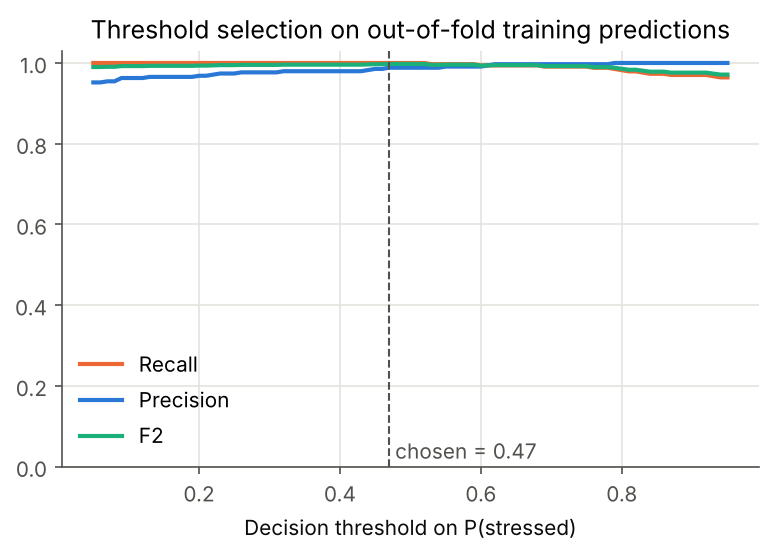

In [14]:
thr, thr_df = T.choose_threshold(y_train.values, oof_final)
print("chosen threshold:", thr)
print(thr_df[thr_df.threshold.isin([0.3, 0.4, thr, 0.5, 0.6])].round(4).to_string(index=False))
fig("threshold_selection.png", 600)

### 2e. Final held-out test evaluation (the test set is used once, here)

The final pipeline is refit on all 960 training rows and scored on the 240 test rows. For context, the
untuned logistic-regression baseline and the dummy are fitted on the same training data and scored on the
same test rows. That comparison doesn't choose anything; every choice was made earlier using CV.

In [15]:
test_res, test_proba = T.evaluate_on_test(final_pipe, make_pipeline(base_estimators()["logreg"]),
                                          make_pipeline(base_estimators()["dummy_majority"]),
                                          train_df, y_train, test_df, y_test, thr)
pd.DataFrame(test_res).T[["threshold","accuracy","precision","recall","f1","roc_auc","average_precision","tn","fp","fn","tp"]]

,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp
final_at_chosen_threshold,0.47,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,156.0,0.0,0.0,84.0
final_at_0.5,0.50,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,156.0,0.0,0.0,84.0
baseline_logreg_at_0.5,0.50,0.9708,0.9753,0.9405,0.9576,0.9981,0.9965,154.0,2.0,5.0,79.0
dummy_majority_at_0.5,0.50,0.6500,0.0000,0.0000,0.0000,0.5000,0.3500,156.0,0.0,84.0,0.0


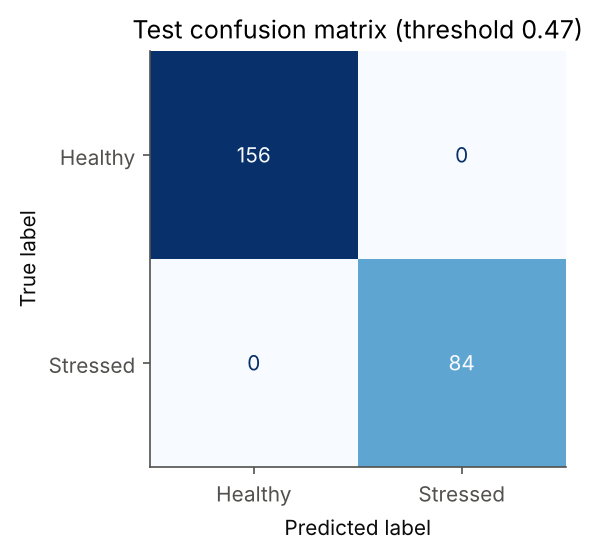

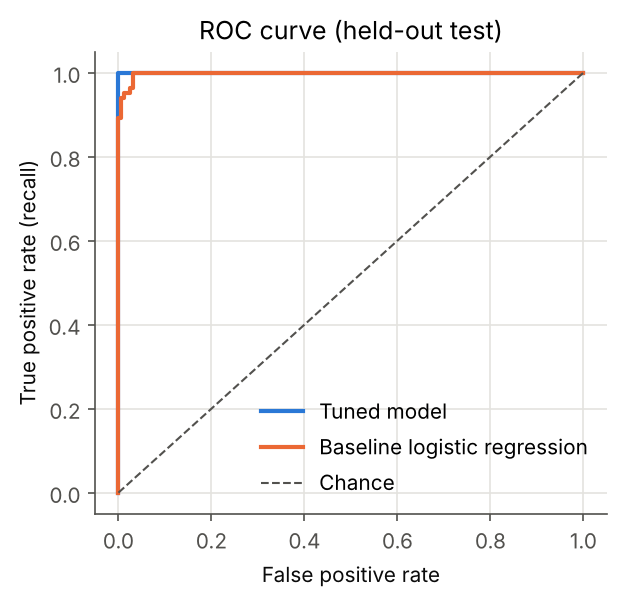

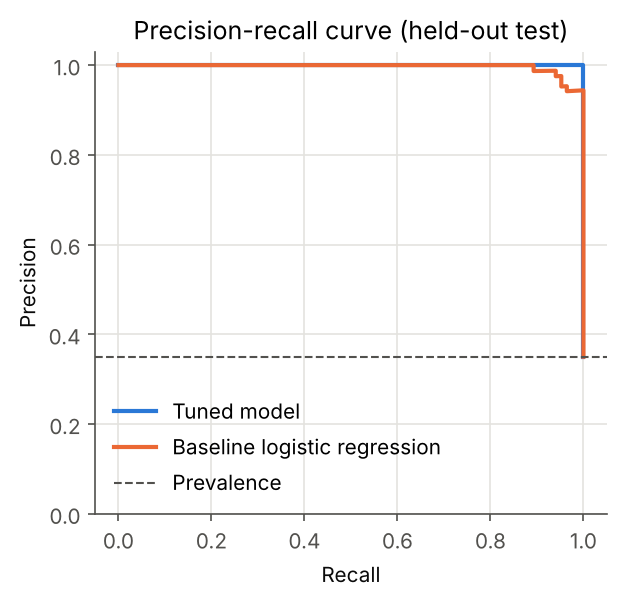

In [16]:
fig("confusion_matrix.png", 360); fig("roc_curve.png", 400); fig("pr_curve.png", 400)

**Reading the result.** The tuned model classifies all 240 test rows correctly. The untuned baseline logistic
regression misses 5 stressed rows and raises 2 false alarms. Its stronger default regularisation (C = 1) shrinks
the coefficients and blurs the boundary. A perfect test score is only believable because the label is a linear
formula of the inputs (Section 1). On real field data I would expect, and would want to report, a clearly lower
number.

## 3. Explainability: SHAP and permutation importance

Background dataset has 960 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=960 when initializing the masker.


mean |SHAP| (log-odds), test set:
ndvi_mean          42.7576
canopy_density     23.7973
moisture_index     19.6177
nir_reflectance     0.3077
red_edge_2          0.2777
soil_brightness     0.2371
ndvi_std            0.1819
red_edge_1          0.0483


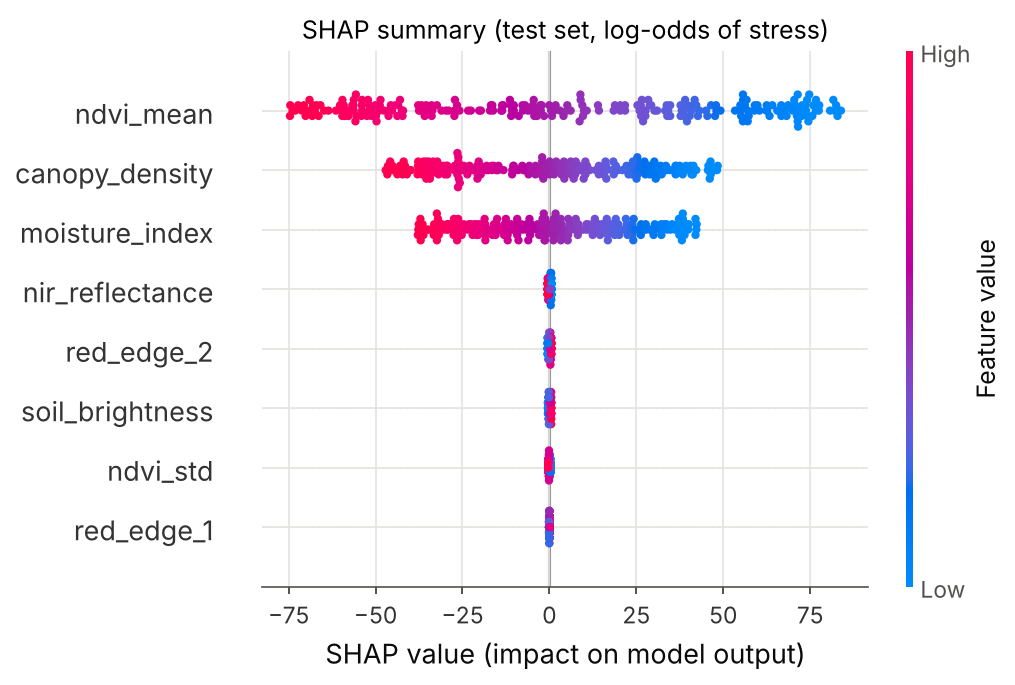

In [17]:
shap_rank, perm = T.explain(final_pipe, train_df, test_df, y_test)
print("mean |SHAP| (log-odds), test set:"); print(shap_rank.round(4).to_string())
fig("shap_summary.png", 650)

        feature  importance_mean  importance_std
      ndvi_mean          0.35097         0.03628
 canopy_density          0.11364         0.01507
 moisture_index          0.06912         0.00963
       ndvi_std          0.00000         0.00000
     red_edge_2          0.00000         0.00000
     red_edge_1          0.00000         0.00000
soil_brightness          0.00000         0.00000
nir_reflectance          0.00000         0.00000


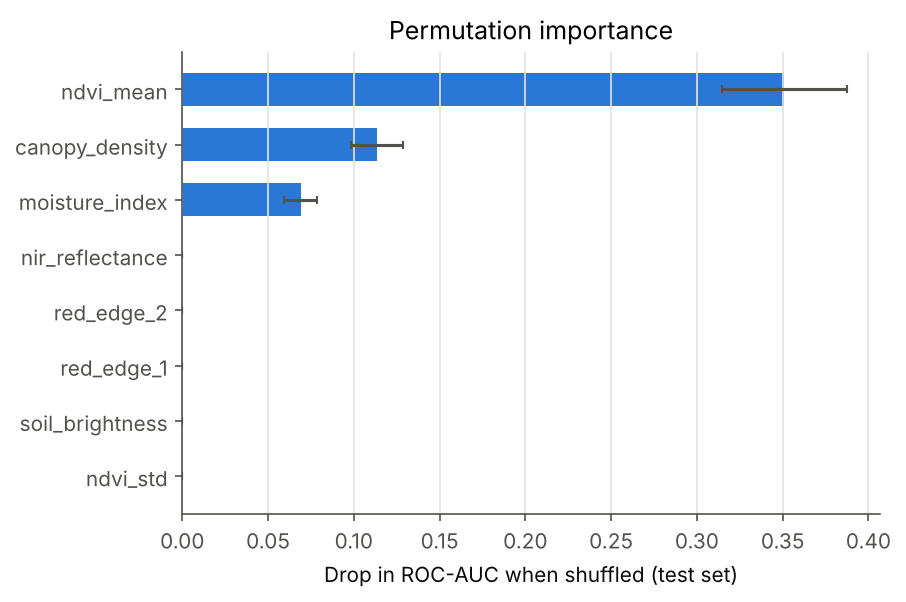

In [18]:
print(perm.round(5).to_string(index=False))
fig("permutation_importance.png", 550)

**Agronomic reading.** Both methods agree on the same top three, in the same order:
1. **NDVI mean** (photosynthetic vigour). Low NDVI pushes strongly toward *Stressed*. This is the classic
   chlorophyll/biomass signal.
2. **Canopy density.** Thin canopy (poor stand, gaps, lodging) adds to stress risk even when the remaining
   leaves look green.
3. **Moisture index.** Dry canopies are flagged. Water stress often comes before visible greenness loss, so this
   is an early-warning channel.

Red-edge, NIR, soil brightness and NDVI spread contribute close to zero. In this synthetic data they are
unrelated to the label. In real data, red-edge in particular would be expected to matter for early stress.
That is a good example of why the importances describe *this dataset's* labelling process and not plant
physiology in general.

## 4. Spatial analysis: field-level stress map

The test set alone covers only 240 rows over 400 cells, which is too sparse for a map. So every one of the
1,200 rows is scored **out-of-fold** (5-fold, final pipeline config): each row is predicted by a model that
never saw it. Predictions are then averaged per `(grid_x, grid_y)` cell.

{'oof_roc_auc_all_rows': 1.0, 'cells_occupied': 379, 'cells_empty': 21, 'corr_cell_pred_vs_observed': 0.9942, 'severity_counts': {'Low': 145, 'Moderate': 127, 'High': 67, 'Critical': 40}, 'severity_share_of_cells': {'Low': 0.383, 'Moderate': 0.335, 'High': 0.177, 'Critical': 0.106}, 'morans_i': -0.0075, 'morans_i_expected_random': -0.0026, 'morans_i_p_value': 0.543, 'stressed_rate_by_grid_x_range': [0.25, 0.541], 'stressed_rate_by_grid_y_range': [0.25, 0.459]}


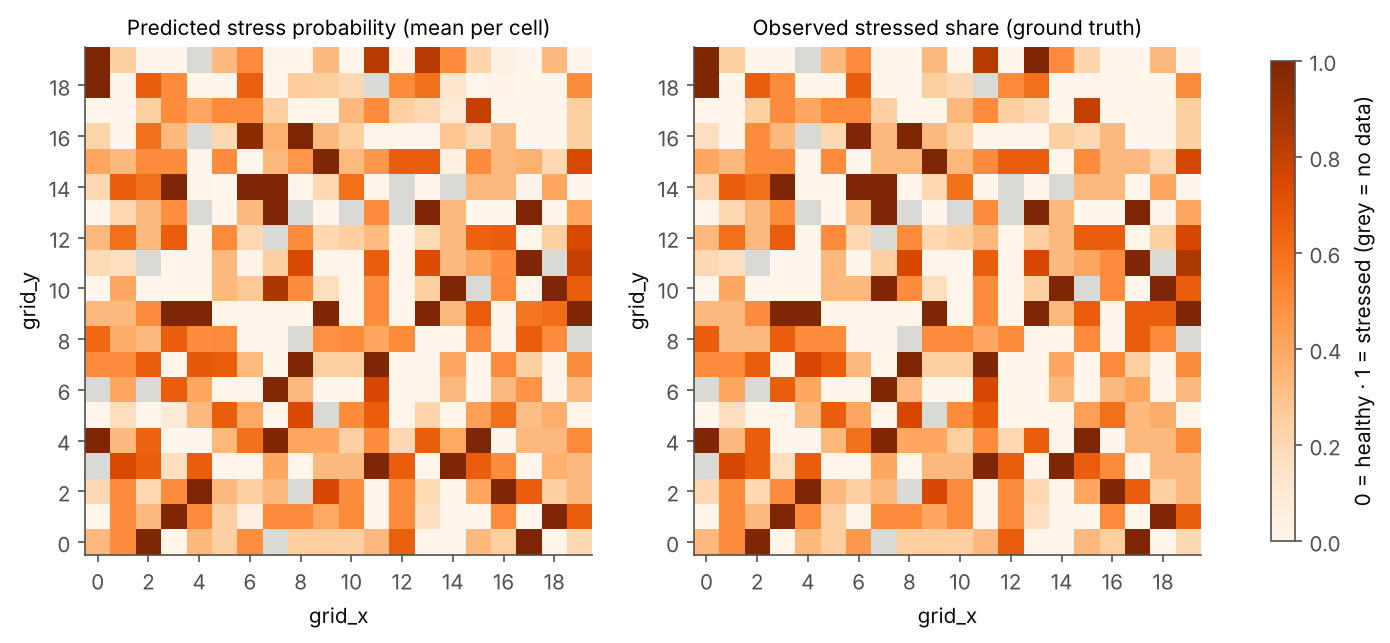

In [19]:
sp, cells = T.spatial(df, clone(final_pipe))
print({k: v for k, v in sp.items() if k != "top10_cells"})
fig("stress_heatmap.png")

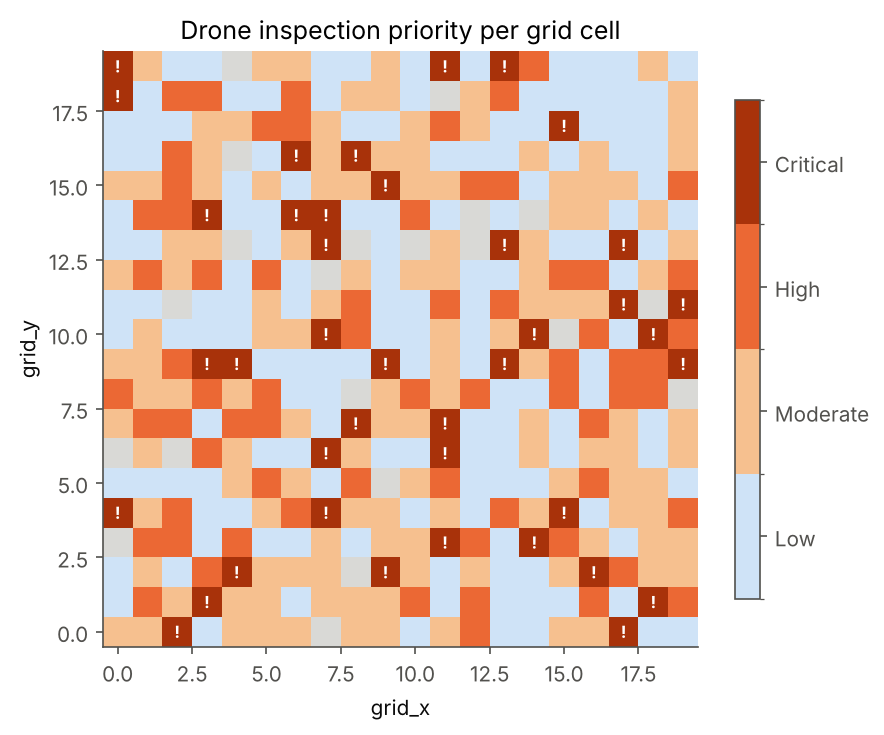

,grid_x,grid_y,mean_proba,max_proba,observed_rate,n_obs,severity
0,7,13,1.0,1.0,1.0,3,Critical
1,15,4,1.0,1.0,1.0,2,Critical
2,0,18,1.0,1.0,1.0,1,Critical
3,0,19,1.0,1.0,1.0,1,Critical
4,3,1,1.0,1.0,1.0,1,Critical
5,4,9,1.0,1.0,1.0,1,Critical
6,6,14,1.0,1.0,1.0,1,Critical
7,8,16,1.0,1.0,1.0,1,Critical
8,17,0,1.0,1.0,1.0,1,Critical
9,17,11,1.0,1.0,1.0,1,Critical


In [20]:
fig("severity_map.png", 520)
pd.DataFrame(sp["top10_cells"])

**Spatial findings**
* The predicted map tracks the ground truth almost exactly (cell-level r ≈ 0.99), as expected given the test metrics.
* **Moran's I ≈ 0 (permutation p ≈ 0.54):** stress is **not spatially clustered**. Stressed cells are scattered
  across the field rather than forming patches, and there is no trend along `grid_x` or `grid_y` either. Real
  stress (drainage, pests, soil zones) is usually clustered, so this is another sign of synthetic data. It also
  changes the drone plan: cell-by-cell targeting, not zone sweeps.
* 21 of 400 cells have no observation (grey). The mean is 3.2 observations per cell, so many cell values rest on
  1–2 points.

## 5. Drone & agronomy interpretation

Severity tier per cell = mean predicted stress probability: **Low** < 0.25 ≤ **Moderate** < 0.5 ≤ **High** < 0.75 ≤ **Critical**.

In [21]:
tiers = pd.DataFrame({"cells": sp["severity_counts"], "share_of_occupied_cells": sp["severity_share_of_cells"]})
tiers

,cells,share_of_occupied_cells
Low,145,0.383
Moderate,127,0.335
High,67,0.177
Critical,40,0.106


| Tier | Recommended drone action |
|---|---|
| **Critical** (≥ 0.75) | Re-fly within 24–48 h at low altitude (about 15–30 m, ~1–2 cm/px) with multispectral + RGB, and add a thermal camera if available to confirm water stress. Send a scout with GPS waypoints for ground truth (soil moisture probe, leaf/tissue sample). Candidate for spot-spraying or variable-rate irrigation/fertiliser. |
| **High** (0.5–0.75) | Targeted re-flight within the week on a waypoint mission over just these cells, with oblique RGB to check pests/disease. Prioritise cells next to Critical ones. |
| **Moderate** (0.25–0.5) | Keep in the routine survey but increase frequency (e.g. weekly instead of fortnightly). Watch the trend: two rising flights in a row promote a cell to High. |
| **Low** (< 0.25) | Routine whole-field survey at normal altitude (about 80–120 m) on the regular schedule. |

Because stress is **not clustered** here (Moran's I ≈ 0), the efficient mission is a **waypoint route through
the Critical + High cells** (order them with a travelling-salesman heuristic) rather than lawn-mowing a
sub-area. With real, clustered stress, the same tiers would instead define polygons for area-based re-flights.

## 6. Robustness checks

In [22]:
rob = T.robustness(train_df, y_train, final_pipe)
rob

{'spatial_block_cv': {'f1_mean': 0.9927,
  'f1_std': 0.008,
  'roc_auc_mean': 1.0,
  'roc_auc_std': 0.0},
 'ablation_without_ndvi_mean_canopy_moisture_logreg': {'features': ['ndvi_std',
   'ndvi_min',
   'ndvi_max',
   'gndvi',
   'savi',
   'evi',
   'red_edge_1',
   'red_edge_2',
   'nir_reflectance',
   'soil_brightness'],
  'f1_mean': 0.759,
  'f1_std': 0.0506,
  'roc_auc_mean': 0.8992,
  'roc_auc_std': 0.0208}}

* **Spatial-block CV** (holding out whole 5×5-cell blocks) gives the same scores as random CV. Because stress
  isn't spatially autocorrelated, neighbouring observations don't leak information between folds here.
* **Ablation:** without the three label-defining features, logistic regression drops to about F1 0.76 and ROC-AUC 0.90.
  The remaining NDVI-family columns are noisy copies of NDVI mean. This is a more realistic picture of how
  hard the task becomes when the "formula" inputs aren't all observed.

## 7. Reflection: limitations and improvements with real-world data

**Limitations**
* The label is a deterministic function of three inputs, so the near-perfect scores show the model learned the
  rule, not that it detects field stress this well.
* Inter-band relationships aren't physical (NIR independent of NDVI, NDVI > 1), and stress isn't spatially clustered.
* There is a single field and a single date: no temporal dynamics, crop type, growth stage, weather, or soil information.
* The grid has 1–11 observations per cell, so cell estimates are noisy and 21 cells are empty.

**Improvements with real data**
1. Ground-truth labels from scouting/agronomist assessment, and multiple stress *types* (water, nitrogen, disease) as a multi-class target.
2. Raw reflectance bands with radiometric calibration (reflectance panels, sun sensor), so indices are physically consistent and can be recomputed.
3. Multi-temporal flights: change in NDVI/red-edge between dates is a stronger early-stress signal than a single snapshot.
4. Thermal imagery (canopy temperature / CWSI) for water stress, plus weather, soil maps and irrigation logs.
5. Spatial models: neighbourhood features, CNNs on image patches, and spatial-block or field-level CV to measure transfer to new fields.
6. Probability calibration and monitoring for drift across seasons, sensors and crops.

## 8. Reproducibility check against `python -m src.train`

In [23]:
ref = json.loads((REPORTS_DIR / "metrics.json").read_text())
checks = {
    "cv logreg f1": (cv_df.set_index("model").loc["logreg", "f1_mean"], next(r for r in ref["cv_comparison"] if r["model"] == "logreg")["f1_mean"]),
    "tuned best f1": (tuned[best_name][0]["f1_mean"], ref["tuned"][ref["best_tuned_model"]]["f1_mean"]),
    "threshold": (thr, ref["threshold"]["chosen"]),
    "test f1": (test_res["final_at_chosen_threshold"]["f1"], ref["test"]["final_at_chosen_threshold"]["f1"]),
    "test roc_auc": (test_res["final_at_chosen_threshold"]["roc_auc"], ref["test"]["final_at_chosen_threshold"]["roc_auc"]),
    "baseline test f1": (test_res["baseline_logreg_at_0.5"]["f1"], ref["test"]["baseline_logreg_at_0.5"]["f1"]),
    "top SHAP features": (list(shap_rank.index[:3]), list(ref["shap_mean_abs"])[:3]),
    "Moran's I": (sp["morans_i"], ref["spatial"]["morans_i"]),
}
for k, (a, b) in checks.items():
    print(f"{k:20s} notebook={a}  script={b}  {'OK' if a == b else 'MISMATCH'}")
assert all(a == b for a, b in checks.values())

cv logreg f1         notebook=0.9685  script=0.9685  OK
tuned best f1        notebook=0.9912  script=0.9912  OK
threshold            notebook=0.47  script=0.47  OK
test f1              notebook=1.0  script=1.0  OK
test roc_auc         notebook=1.0  script=1.0  OK
baseline test f1     notebook=0.9576  script=0.9576  OK
top SHAP features    notebook=['ndvi_mean', 'canopy_density', 'moisture_index']  script=['ndvi_mean', 'canopy_density', 'moisture_index']  OK
Moran's I            notebook=-0.0075  script=-0.0075  OK
